## Instalando pacotes

In [ ]:
!apt-get update -qq
!apt-get install -y openslide-tools libopenslide0

In [ ]:
!pip install openslide-python
!pip install kfbslide

## Setup

In [5]:
import json
import uuid
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import openslide, kfbslide

from skimage.filters import threshold_otsu
from skimage.color import rgb2hsv

import torch
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import v2
from torchvision.io import decode_image

In [4]:
from google.colab import drive
drive.mount('/content/drive')

base_dir = "/content/drive/MyDrive/Lucas"

Mounted at /content/drive


## Extração de tiles

In [ ]:
def extract_tiles(slide_path, save_path, tile_size=224):
    # Abertura da lâmina e verificação de magnificação 20x
    s = kfbslide.OpenSlide(Path(slide_path))
    if int(s.properties.get("openslide.objective-power")) != 40:
        s.close()
        return
    if int(s.level_downsamples[1]) != 2:
        s.close()
        return

    # Otsu na lâmina toda (miniatura)
    lv_thumb = s.get_best_level_for_downsample(32)
    thumb = s.read_region((0, 0), lv_thumb, s.level_dimensions[lv_thumb]).convert("L")
    thr = threshold_otsu(np.asarray(thumb))
    total_area = tile_size * tile_size

    # Pasta de saída
    out_dir = Path(save_path)
    out_dir.mkdir(parents=True, exist_ok=True)

    # Extração de tiles
    level = 1
    step = tile_size * 2
    W, H = s.dimensions
    count = 0
    for y in range(0, H-step+1, step):
        for x in range(0, W-step+1, step):

            region = s.read_region((x, y), level, (tile_size, tile_size))
            if np.asarray(region)[..., 3].min() == 0:
                continue
            img = region.convert("RGB")

            gray = np.asarray(img.convert("L"))
            mask = gray < thr

            cell_area = mask.sum()
            if (cell_area / total_area) < 0.20:
              continue

            # Evita tiles 'sujos'
            px = np.asarray(img)[mask].reshape(-1, 1, 3)
            if np.median(rgb2hsv(px / 255.0)[..., 0]) * 360 < 180:
              continue

            img.save(out_dir / (str(count) + f"_{x}_{y}" + ".png"))
            count += 1

    s.close()

In [7]:
slide_name = "2024-10-14_08_37_27CYT"         # Troque aqui o nome da lâmina
slide_path = base_dir + "/" + slide_name + ".kfb"
save_path = base_dir + "/Slides/" + slide_name
local_path = '/content' + "/" + slide_name

if not os.path.exists(save_path):
  os.makedirs(save_path)
  extract_tiles(slide_path, save_path)
else:
  print("Extração de tiles já feita")

Extração de tiles já feita


## Copiando pasta para o ambiente de execução

In [ ]:
import shutil

shutil.copytree(save_path, local_path, dirs_exist_ok=True)

'/content/2024-10-14_08_29_15CYT'

In [ ]:
total = sum(
    len(arquivos)
    for _, _, arquivos in os.walk(save_path)
)
total_amb = sum(
    len(arquivos)
    for _, _, arquivos in os.walk(local_path)
)

print(f"Total de tiles (drive): {total}")
print(f"Total de tiles (amb): {total_amb}")

if total_amb != total:
  raise Exception(f"Total de tiles do ambiente de execução difere do drive")
else:
  print("Quantidade de tiles igual entre drive e ambiente de execução")

Total de tiles (drive): 2006
Total de tiles (amb): 2006
Quantidade de tiles igual entre drive e ambiente de execução


## Carregando tiles como dataset

In [8]:
tiles_names = []
sorted(tiles_names)
for arquivo in os.listdir(save_path):
  tiles_names.append(str(arquivo))

tiles_annotation = pd.DataFrame(sorted(tiles_names, key=lambda x: int(x.split("_")[0])))
tiles_annotation

,0
0,0_44352_2240.png
1,1_43456_2688.png
2,2_50176_2688.png
3,3_51072_2688.png
4,4_51520_2688.png
...,...
1959,1959_42112_87808.png
1960,1960_48832_88256.png
1961,1961_51072_88256.png
1962,1962_48832_88704.png


In [ ]:
class Tiles_raw(Dataset):
    def __init__(self, annotations, img_dir, transform=None):
        self.annotations = annotations
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.annotations)

    def __getitem__(self, idx):
        img_path = self.img_dir + "/" + self.annotations.iloc[idx][0]
        image = decode_image(img_path)
        if self.transform:
            image = self.transform(image)
        return image

In [ ]:
transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True), v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])])

tiles_raw_dataset = Tiles_raw(tiles_annotation, local_path, transform)
tiles_raw_dataloader = DataLoader(tiles_raw_dataset, batch_size=64)

## Carregando UniCAS

In [ ]:
'''
Créditos: https://github.com/peter-fei/UniCAS
'''
import functools
import torch
import timm

# Define UniCAS parameters
params = {
    'patch_size': 16,
    'embed_dim': 1024,
    'depth': 24,
    'num_heads': 16,
    'init_values': 1e-5,
    'mlp_ratio': 2.671875 * 2,
    'mlp_layer': functools.partial(timm.layers.mlp.GluMlp, gate_last=False),
    'act_layer': torch.nn.SiLU,
    'no_embed_class': False,
    'img_size': 224,
    'num_classes': 0,
    'in_chans': 3,
}

# Build model
backbone = timm.models.VisionTransformer(**params)

# Load checkpoint
# Ensure 'UniCAS.pth' is in your current directory
state = torch.load(base_dir + "/" + "UniCAS.pth", map_location='cpu')
print(backbone.load_state_dict(state, strict=False))

# Inference example
backbone.eval()
if torch.cuda.is_available():
    backbone = backbone.cuda()

with torch.no_grad():
    # Input: [Batch, Channels, Height, Width]
    x = torch.randn(1, 3, 224, 224)
    if torch.cuda.is_available():
        x = x.cuda()
    out = backbone(x)
    print('Output feature shape:', out.shape) # Expected: [1, 1024]

<All keys matched successfully>
Output feature shape: torch.Size([1, 1024])


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
for param in backbone.parameters():
    param.requires_grad = False

## Extração de embeddings dos tiles com UniCAS

In [ ]:
backbone = backbone.to(device)

embeddings = []
with torch.no_grad():
  for X in tiles_raw_dataloader:
    X = X.to(device)
    embedding = backbone(X)
    embeddings.append(embedding.cpu())

torch_embeddings = torch.cat(embeddings, dim=0)
torch.save(torch_embeddings, base_dir + "/Embeddings/" +"embeddings_" + slide_name + ".pt")

In [12]:
torch_embeddings = torch.load(base_dir + "/Embeddings/" + "embeddings_" + slide_name + ".pt")
torch_embeddings.shape

torch.Size([1964, 1024])

## Carregando ambil_topk.pth (treinado sobre o BMT, com UniCAS como backbone)

In [10]:
'''
Feito com auxílio do  Claude Code (Opus 5.5 / High)
'''

import torch.nn as nn

class GatedAttentionMIL(nn.Module):
    """ABMIL com atenção com porta (Ilse et al., 2018)."""

    def __init__(self, topk=8, in_dim=1024, hid=256, att_hid=128, n_classes=3, p_drop=0.25):
        super().__init__()
        self.topk = topk
        # projeção: reduz 1024 → 256 antes da atenção
        self.proj = nn.Sequential(
            nn.Linear(in_dim, hid),
            nn.ReLU(),
            nn.Dropout(p_drop),
        )
        # dois ramos da atenção com porta
        self.att_V = nn.Sequential(nn.Linear(hid, att_hid), nn.Tanh())
        self.att_U = nn.Sequential(nn.Linear(hid, att_hid), nn.Sigmoid())
        self.att_w = nn.Linear(att_hid, 1)

        self.classifier = nn.Linear(hid, n_classes)

    def topk_idx(self, tensor, k):
        '''
        tensor.shape == [1,N,3]
        Função topk recebe os logits da classificação e retorna os índices dos topk
        tiles suspeitos com base no score (P(lsil) + P(hsil)) / P(nil)
        '''
        tensor = tensor.squeeze(0)  # [N,3]
        scores = []
        for logits in tensor:
          nil_score =  logits[0].item()
          lsil_score = logits[1].item()
          hsil_score = logits[2].item()

          p = torch.softmax(torch.tensor([nil_score,lsil_score,hsil_score]),dim=0)

          score = (p[1].item() + p[2].item()) / max(p[0].item(), 1e-12)         # Evita divisão por zero
          scores.append(score)

        scores = torch.tensor(scores)
        _, idx = torch.topk(scores,k)
        idx = idx.flatten()
        return idx

    def forward(self, bags):                    # bags: [B, N, 1024]
        h = self.proj(bags)                     # [B, N, 256]

        if self.topk == -1:
          topk = h.shape[1]
        else:
          topk = min(self.topk, h.shape[1])

        h_proj = self.classifier(h)
        idx = self.topk_idx(h_proj,topk)

        h = h[:,idx]

        a = self.att_w(self.att_V(h) * self.att_U(h))   # [B, topk, 1]
        a = torch.softmax(a, dim=1)                     # pesos somam 1 no bag

        z = (a * h).sum(dim=1)              # [B, 256] — bag embedding

        return self.classifier(z), h_proj[:,idx], idx

In [11]:
device = "cuda" if torch.cuda.is_available() else "cpu"
abmil = GatedAttentionMIL().to(device)
state = torch.load(base_dir + "/abmil_topk.pth", map_location='cpu')
abmil.load_state_dict(state)

for param in abmil.parameters():
    param.requires_grad = False

## Inferência na lâmina

In [ ]:
abmil.eval()
with torch.no_grad():
  X = torch_embeddings.unsqueeze(0)
  X = X.to(device)

  y, h_proj, idx = abmil(X)

In [ ]:
labels = {0: 'NIL', 1: 'LSIL', 2: 'HSIL'}
idx = [i.item() for i in idx]
h_proj = h_proj.squeeze(0)

In [ ]:
print("--------------------------------------------")
print(slide_name)
print()
print("Classificação da lâmina:", labels[y.argmax().item()])
print()
print("índices dos top-k tiles suspeitos:")
print(idx)
print()
print("Logits de cada tile do top-k suspeitos:")
print(h_proj)
print("--------------------------------------------")

--------------------------------------------
2024-10-14_08_37_27CYT

Classificação da lâmina: LSIL

índices dos top-k tiles suspeitos:
[1555, 241, 1167, 1514, 1391, 209, 350, 593]

Logits de cada tile do top-k suspeitos:
tensor([[-18.6341,  10.0204,   1.9426],
        [-16.6483,  -2.6922,  14.2663],
        [-18.9588,  10.8362,   1.4639],
        [-18.9152,   2.6596,   9.2861],
        [-21.7667, -12.7412,  26.2208],
        [-17.3437,  15.5829,  -5.3919],
        [-15.6798,  -2.6677,  11.6116],
        [-14.4924,  12.2691,  -7.1187]])
--------------------------------------------


## Visualização dos top-k tiles suspeitos

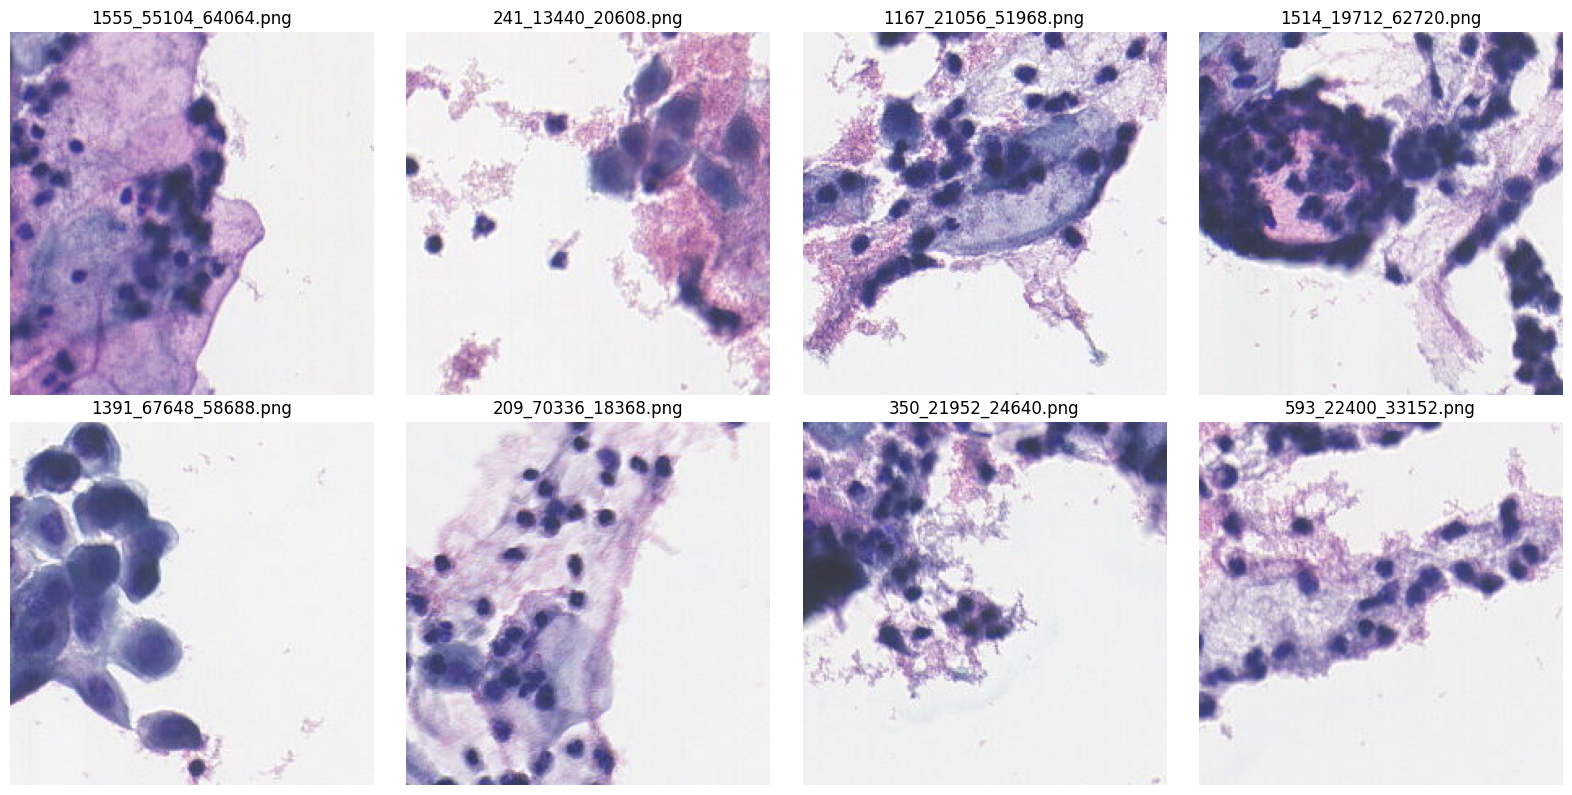

In [ ]:
from PIL import Image

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i, ax in zip(idx, axes.flat):
    filename = tiles_annotation.iloc[i][0]
    img = Image.open(save_path + "/" + filename)

    ax.imshow(img)
    ax.set_title(filename)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Criando anotação para visualização via KFSlideOS

In [ ]:
annotations = []

w = 448  # 224 px no nível 1 = 448 px no nível 0
for i,j in enumerate(idx):
  tile = str(tiles_annotation.iloc[j][0]).split(".")[0]

  x_coord = int(tile.split("_")[1])
  y_coord = int(tile.split("_")[2])

  annotations.append({
      "guid": str(uuid.uuid4()), "name": f"tile_id {j}",
              "description": f"Coords: x={x_coord} y={y_coord} // Predicted label (tile): {labels[h_proj[i].argmax().item()]} // Priority: {i+1} // Predicted label (slide): {labels[y.argmax().item()]}",
      "type": "Rectangle", "scale": 0.5, "width": 3, "color": 0xFF0000, "visible": True,
      "region": {"x": x_coord, "y": y_coord, "width": w, "height": w},
      "points": [{"x": x_coord, "y": y_coord}, {"x": x_coord + w, "y": y_coord}, {"x": x_coord, "y": y_coord + w}, {"x": x_coord + w, "y": y_coord + w}],
      "imageId": 0, "imageindex": 0, "isAllShow": False, "isAlwaysShowDesc": False,
      "fontUnderLine": False, "fontSize": 12, "fontFamily": "Arial", "fontItalic": False, "fontBold": False,
      "measurement": False, "radius": 0, "arcLength": 0, "angle": 0, "RectMarkCount": 0,
  })

out = Path(base_dir) / Path(f"Annotations/{slide_name}_kfb") / Path("Annotations") /"1.json"
out.parent.mkdir(parents=True, exist_ok=True)
out.write_text(json.dumps(annotations))

5788

## Scores de todos os tiles

In [13]:
'''
Feito com auxílio do  Claude Code (Opus 5.5 / High)
'''

import torch.nn as nn

class GatedAttentionMIL(nn.Module):
    """ABMIL com atenção com porta (Ilse et al., 2018)."""

    def __init__(self, in_dim=1024, hid=256, att_hid=128, n_classes=3, p_drop=0.25):
        super().__init__()
        # projeção: reduz 1024 → 256 antes da atenção
        self.proj = nn.Sequential(
            nn.Linear(in_dim, hid),
            nn.ReLU(),
            nn.Dropout(p_drop),
        )
        # dois ramos da atenção com porta
        self.att_V = nn.Sequential(nn.Linear(hid, att_hid), nn.Tanh())
        self.att_U = nn.Sequential(nn.Linear(hid, att_hid), nn.Sigmoid())
        self.att_w = nn.Linear(att_hid, 1)

        self.classifier = nn.Linear(hid, n_classes)

    def scores(self, tensor):
        '''
        tensor.shape == [1,N,3]
        Função topk recebe os logits da classificação e retorna os índices dos topk
        tiles suspeitos com base no score (P(lsil) + P(hsil)) / P(nil)
        '''
        tensor = tensor.squeeze(0)  # [N,3]
        nil_scores = []
        lsil_scores = []
        hsil_scores = []
        for logits in tensor:
          nil_score =  logits[0].item()
          lsil_score = logits[1].item()
          hsil_score = logits[2].item()

          if nil_score == max(nil_score,lsil_score,hsil_score):
            nil_scores.append([nil_score,lsil_score,hsil_score])
          elif lsil_score == max(nil_score,lsil_score,hsil_score):
            lsil_scores.append([nil_score,lsil_score,hsil_score])
          else:
            hsil_scores.append([nil_score,lsil_score,hsil_score])

        return nil_scores, lsil_scores, hsil_scores

    def forward(self, bags):                    # bags: [B, N, 1024]
        h = self.proj(bags)                     # [B, N, 256]
        h_proj = self.classifier(h)

        return self.scores(h_proj)              # [nil_scores,lsil_scores,hsil_scores]

In [14]:
device = "cuda" if torch.cuda.is_available() else "cpu"
abmil = GatedAttentionMIL().to(device)
state = torch.load(base_dir + "/abmil_topk.pth", map_location='cpu')
abmil.load_state_dict(state)

for param in abmil.parameters():
    param.requires_grad = False

In [15]:
abmil.eval()
with torch.no_grad():
  X = torch_embeddings.unsqueeze(0)
  X = X.to(device)

  nil_scores, lsil_scores, hsil_scores = abmil(X)

In [16]:
print(slide_name)
print()
print(f"Quantidade total de tiles: {tiles_annotation.shape[0]}")
print(f"[NIL] {len(nil_scores)} ({(100 * len(nil_scores) / tiles_annotation.shape[0]):.2f}%)")
print(f"[LSIL] {len(lsil_scores)} ({(100 * len(lsil_scores) / tiles_annotation.shape[0]):.2f}%)")
print(f"[HISL] {len(hsil_scores)} ({(100 * len(hsil_scores) / tiles_annotation.shape[0]):.2f}%)")

2024-10-14_08_37_27CYT

Quantidade total de tiles: 1964
[NIL] 474 (24.13%)
[LSIL] 608 (30.96%)
[HISL] 882 (44.91%)


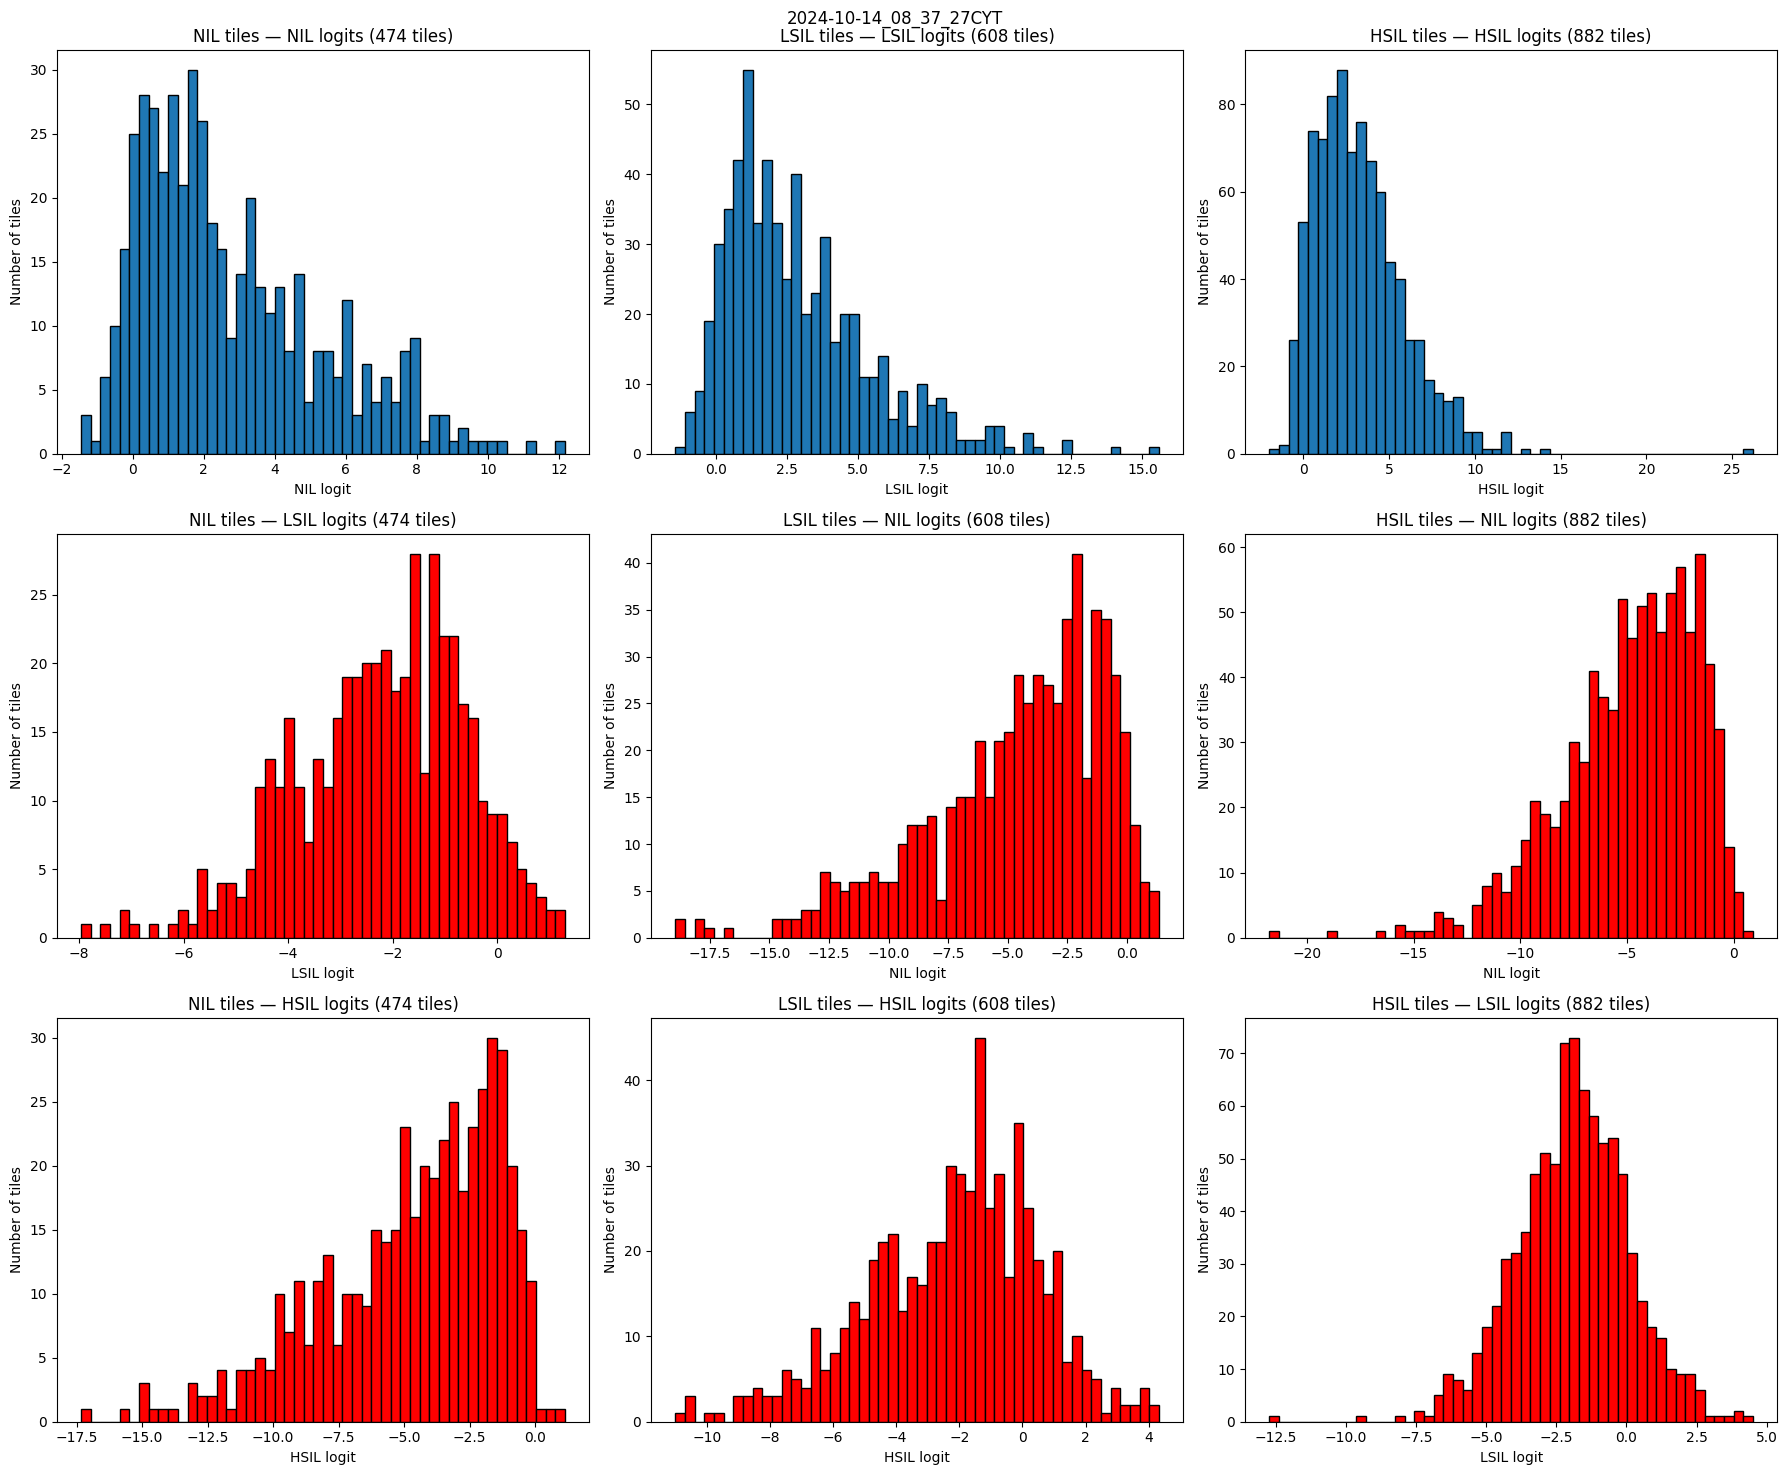

In [17]:
classes = ["NIL", "LSIL", "HSIL"]
groups = [nil_scores, lsil_scores, hsil_scores]

rows = [
    [0, 1, 2],  # nil_scores/nil   lsil_scores/lsil  hsil_scores/hsil
    [1, 0, 0],  # nil_scores/lsil  lsil_scores/nil   hsil_scores/nil
    [2, 2, 1],  # nil_scores/hsil  lsil_scores/hsil  hsil_scores/lsil
]

fig, axes = plt.subplots(3, 3, figsize=(18, 15))

for r, row in enumerate(rows):
    for c, (group_name, scores) in enumerate(zip(classes, groups)):
        ax = axes[r, c]
        col = row[c]
        values = np.array(scores)[:, col] if len(scores) > 0 else np.array([])
        ax.hist(values, bins=50, edgecolor="black", color=None if r == 0 else "red")
        ax.set_xlabel(f"{classes[col]} logit")
        ax.set_ylabel("Number of tiles")
        ax.set_title(f"{group_name} tiles — {classes[col]} logits ({len(values)} tiles)")

fig.suptitle(slide_name)
plt.tight_layout()
plt.show()